# Lab 13-03 · Magnetostatics and Inductance

Companion to [chapter 13-03](../../chapters/13-03-magnetostatics-and-inductance.md). Four parts: the Biot–Savart law for a circular loop; the inductance of a finite solenoid from loop-by-loop mutual inductances; the partial inductance of a bond wire from the Neumann integral; and a gapped core with a saturating $B$–$H$ curve. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, dblquad
from scipy.optimize import brentq
from scipy.special import ellipe, ellipkm1
mu0 = 4e-7 * math.pi  # within a part in 1e9 of the measured value

## Part 1 · The Biot–Savart law for a loop

Approximate a loop of radius $R$ by a regular polygon of $n$ straight sides inscribed in it, chop each side into short elements, add $d\vec{B} = (\mu_0I/4\pi)\,d\vec\ell \times \vec{R}/R^3$ from every element, and compare the on-axis field with the closed form for the circle, $\mu_0IR^2/[2(R^2 + z^2)^{3/2}]$.

**Predict first:** a square ($n$ = 4) inscribed in the circle: is its centre field higher or lower than the circle's? Roughly how many sides do you need for 0.1% accuracy? And what is the field at $z = 2R$, as a fraction of the centre field?

n =   4 sides: centre field 80.0001 uT (circle 62.8319), excess 27.324%
n =   8 sides: centre field 66.2742 uT (circle 62.8319), excess 5.479%
n =  16 sides: centre field 63.6520 uT (circle 62.8319), excess 1.305%
n =  32 sides: centre field 63.0345 uT (circle 62.8319), excess 0.323%
n =  64 sides: centre field 62.8824 uT (circle 62.8319), excess 0.080%
field at z = 2R: 5.620 uT = 0.0894 of the centre field (closed form 5.620 uT)


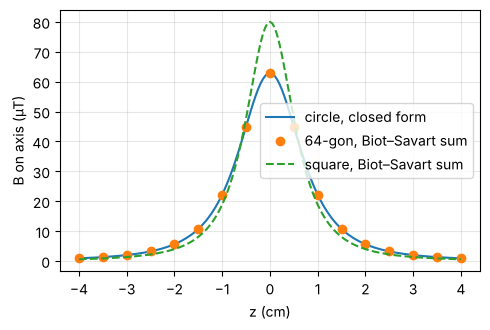

In [2]:
def polygon_field(I, R, point, n, m=400):
    # field of an n-sided polygon inscribed in radius R, each side split into m elements (midpoint rule)
    ang = 2 * math.pi * np.arange(n + 1) / n
    verts = np.stack([R * np.cos(ang), R * np.sin(ang), 0 * ang], axis=1)
    B = np.zeros(3)
    t = (np.arange(m) + 0.5) / m
    for p0, p1 in zip(verts[:-1], verts[1:]):
        src = p0 + np.outer(t, p1 - p0)
        dl = np.tile((p1 - p0) / m, (m, 1))
        r = np.asarray(point) - src
        B += (mu0 * I / (4 * math.pi) * np.cross(dl, r) / np.linalg.norm(r, axis=1)[:, None] ** 3).sum(axis=0)
    return B

R, I = 0.01, 1.0
closed = lambda z: mu0 * I * R**2 / (2 * (R**2 + z**2) ** 1.5)
for n in (4, 8, 16, 32, 64):
    Bc = polygon_field(I, R, [0, 0, 0], n)[2]
    print(f"n = {n:3d} sides: centre field {Bc * 1e6:.4f} uT (circle {closed(0) * 1e6:.4f}), excess {(Bc / closed(0) - 1) * 100:.3f}%")
B2R = polygon_field(I, R, [0, 0, 2 * R], 2048, 10)[2]
print(f"field at z = 2R: {B2R * 1e6:.3f} uT = {B2R / closed(0):.4f} of the centre field (closed form {closed(2 * R) * 1e6:.3f} uT)")
z = np.linspace(-4 * R, 4 * R, 161)
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(z * 100, [closed(zz) * 1e6 for zz in z], label='circle, closed form')
ax.plot(z[::10] * 100, [polygon_field(I, R, [0, 0, zz], 64, 50)[2] * 1e6 for zz in z[::10]], 'o', label='64-gon, Biot–Savart sum')
ax.plot(z * 100, [polygon_field(I, R, [0, 0, zz], 4, 50)[2] * 1e6 for zz in z], '--', label='square, Biot–Savart sum')
ax.set_xlabel('z (cm)'); ax.set_ylabel('B on axis (µT)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · A finite solenoid

A uniform current sheet of $N$ turns on length $\ell$ is a stack of loops. Its inductance is the double sum (here, integral) of the mutual inductances of every pair of loops, using Maxwell's formula for two coaxial loops in terms of the complete elliptic integrals $K$ and $E$. Divide by the long-solenoid value to get the Nagaoka factor.

**Predict first:** at what length, in diameters, does the long formula become 5% too high?

Nagaoka factor at 5 cm: 0.9201
long formula 5% high at length 8.61 cm = 8.6 diameters


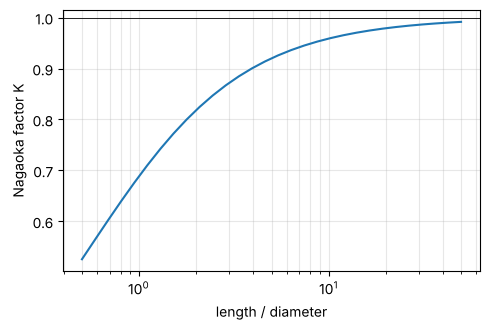

In [3]:
def M_loops(r, sep):
    p = sep**2 / (4 * r**2 + sep**2)          # 1 - k^2, kept exact when the loops nearly coincide
    k = math.sqrt(1 - p)
    return mu0 * r * ((2 / k - k) * ellipkm1(p) - (2 / k) * ellipe(1 - p))

def L_sheet(N, r, ell):
    val, _ = quad(lambda u: (ell - u) * M_loops(r, u), 0, ell, points=[1e-4 * ell, 1e-2 * ell], limit=400)
    return (N / ell) ** 2 * 2 * val

N, r = 200, 5e-3
L_long = lambda ell: mu0 * N**2 * math.pi * r**2 / ell
lengths = np.geomspace(0.005, 0.5, 30)
K = [L_sheet(N, r, ell) / L_long(ell) for ell in lengths]
ell5 = brentq(lambda ell: L_sheet(N, r, ell) / L_long(ell) - 1 / 1.05, 0.02, 0.5)
print(f"Nagaoka factor at 5 cm: {L_sheet(N, r, 0.05) / L_long(0.05):.4f}")
print(f"long formula 5% high at length {ell5 * 100:.2f} cm = {ell5 / (2 * r):.1f} diameters")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.semilogx(lengths / (2 * r), K); ax.axhline(1, color='k', lw=0.6)
ax.set_xlabel('length / diameter'); ax.set_ylabel('Nagaoka factor K'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Part 3 · Bond-wire inductance

The partial self-inductance of a straight wire is the Neumann double integral of $1/\lvert z_1 - z_2\rvert$ over its length, with the filaments separated by the wire radius (the high-frequency case, current on the surface). Compare with the formula $(\mu_0\ell/2\pi)[\ln(2\ell/a) - 1]$ and plot nanohenries per millimetre.

**Predict first:** is "1 nH/mm" too high or too low for a 5 mm bond of 25 µm wire?

0.5 mm: Neumann 0.3407 nH, formula 0.3382 nH, 0.676 nH/mm
1.0 mm: Neumann 0.8175 nH, formula 0.8150 nH, 0.815 nH/mm
2.0 mm: Neumann 1.9098 nH, formula 1.9073 nH, 0.954 nH/mm
3.0 mm: Neumann 3.1068 nH, formula 3.1043 nH, 1.035 nH/mm


4.0 mm: Neumann 4.3717 nH, formula 4.3692 nH, 1.092 nH/mm
5.0 mm: Neumann 5.6871 nH, formula 5.6846 nH, 1.137 nH/mm


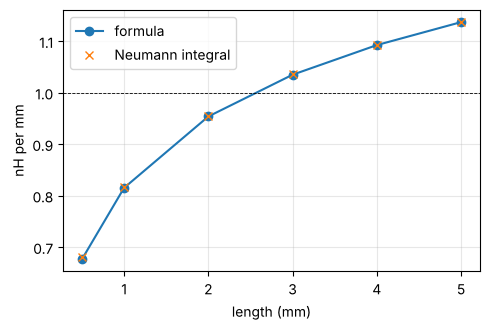

In [4]:
a = 12.5e-6
def L_neumann(ell, d=a):
    val, _ = dblquad(lambda z2, z1: 1 / math.sqrt((z1 - z2) ** 2 + d * d), 0, ell, 0, ell, epsabs=1e-14, epsrel=1e-10)
    return mu0 / (4 * math.pi) * val
formula = lambda ell: mu0 * ell / (2 * math.pi) * (math.log(2 * ell / a) - 1)
ells = np.array([0.5, 1, 2, 3, 4, 5]) * 1e-3
for ell in ells:
    print(f"{ell * 1e3:.1f} mm: Neumann {L_neumann(ell) * 1e9:.4f} nH, formula {formula(ell) * 1e9:.4f} nH, "
          f"{formula(ell) * 1e9 / (ell * 1e3):.3f} nH/mm")
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(ells * 1e3, [formula(e) * 1e9 / (e * 1e3) for e in ells], 'o-', label='formula')
ax.plot(ells * 1e3, [L_neumann(e) * 1e9 / (e * 1e3) for e in ells], 'x', label='Neumann integral')
ax.axhline(1, color='k', lw=0.6, ls='--'); ax.set_xlabel('length (mm)'); ax.set_ylabel('nH per mm'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · A gapped core that saturates

Model the ferrite's $B$–$H$ curve as $B = B_s\tanh(\mu_r\mu_0H/B_s)$ with $\mu_r$ = 2000 and $B_s$ = 0.4 T (illustrative), on Example 13-03.4's core (10 cm path, 1 cm², 100 turns). Ampère's law around the core gives $NI = H_c\ell_c + Bg/\mu_0$, with the same $B$ in core and gap. Solve for $B$ against current with and without the 1 mm gap.

**Predict first:** with the gap, how much more current does it take to reach 0.3 T than without? Is it more or less than the factor of 21 from the linear analysis?

current for 0.3 T: 2.542 A with the gap, 154.9 mA without; ratio 16.4


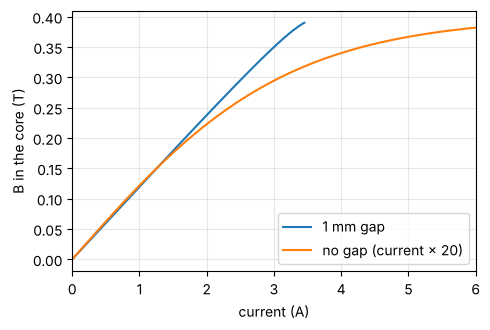

In [5]:
Bs, mur, lc, A, Nt = 0.4, 2000, 0.1, 1e-4, 100
def current_for_B(B, g):
    Hc = Bs / (mur * mu0) * math.atanh(B / Bs)
    return (Hc * lc + B * g / mu0) / Nt
Ig, Iu = current_for_B(0.3, 1e-3), current_for_B(0.3, 0.0)
print(f"current for 0.3 T: {Ig:.3f} A with the gap, {Iu * 1e3:.1f} mA without; ratio {Ig / Iu:.1f}")
Bgrid = np.linspace(0, 0.39, 200)
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot([current_for_B(B, 1e-3) for B in Bgrid], Bgrid, label='1 mm gap')
ax.plot([current_for_B(B, 0.0) * 20 for B in Bgrid], Bgrid, label='no gap (current × 20)')
ax.set_xlabel('current (A)'); ax.set_ylabel('B in the core (T)'); ax.set_xlim(0, 6); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- An inscribed square has a centre field 27% higher than its circle (its sides pass closer to the centre); the excess falls as $(\pi/n)^2/3$, so about 60 sides give 0.1%.
- The long-solenoid formula needs a coil many diameters long before it is accurate to a few per cent.
- "1 nH/mm" is a fair rule for millimetre bonds; the per-millimetre value creeps up with length.
- Near saturation the core needs much more $H$, so the gapped core's advantage in current shrinks below the linear factor of 21, but it still extends the usable current range by more than an order of magnitude.